# 10 — QPOSD: phân lớp và phát hiện dầu/tương tự dầu

SOS vẫn là dữ liệu chính; đây là kiểm tra bổ sung trên UAVSAR L-band.
Nguồn: [QPOSD](https://zenodo.org/records/19258036), CC BY 4.0.
Chia theo nhóm ảnh có giao trùng chính xác (giao thức v2), chưa chứng minh
độc lập cảnh. Tập test đã được xem để kiểm tra ảnh–nhãn, không phải đánh giá mù.
Nhãn tương tự dầu là lớp
chung, chưa phân biệt gió yếu, màng sinh học hay mưa.

**Hai kết quả khác nhau:** phân lớp có sẵn vùng tham chiếu và phát hiện
đầu-cuối từ ảnh. Chỉ bước thứ hai đo đầy đủ việc tìm vùng, hình học và phân
lớp. Toàn bộ lựa chọn dùng validation; test chỉ chạy sau khi đã lưu lựa chọn.
Notebook đọc bằng chứng đã lưu, kiểm tra hash, tổng hợp lại số đếm và chạy
lại suy luận của hai backend trên năm ảnh test, không fit lại mô hình.


In [1]:
from pathlib import Path
import io, json, sys
import numpy as np
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/sar_oil').is_dir())
sys.path.insert(0,str(ROOT))
sys.path.insert(0, str(ROOT))
from scripts._provenance import source_matches
from scripts.qposd.extract_qposd_regions import digest, load_pair
from scripts.qposd.qposd_metrics import detection, summarize_detections, classification
from scripts.qposd.qposd_pipeline import infer
from scripts.qposd.select_qposd_detection import frozen_classifier
from scripts.qposd.evaluate_qposd_test import frozen_detection
base=ROOT/'results/qposd'
protocol=json.loads((base/'protocol.json').read_text())
evaluation=json.loads((base/'evaluation.json').read_text())
classifiers=json.loads((base/'classifier_selection.json').read_text())
candidates=json.loads((base/'detection_selection.json').read_text())
assert evaluation['complete']
assert [r['number'] for r in evaluation['images']]==protocol['splits']['test']
assert source_matches(ROOT/'scripts/qposd/evaluate_qposd_test.py', evaluation['script_sha256'], digest(ROOT/'scripts/qposd/evaluate_qposd_test.py'))
assert source_matches(ROOT/'scripts/qposd/qposd_pipeline.py', evaluation['pipeline_sha256'], digest(ROOT/'scripts/qposd/qposd_pipeline.py'))
assert source_matches(ROOT/'scripts/qposd/qposd_fast_features.py', evaluation['feature_code_sha256'], digest(ROOT/'scripts/qposd/qposd_fast_features.py'))
assert source_matches(ROOT/'scripts/qposd/qposd_metrics.py', evaluation['metrics_sha256'], digest(ROOT/'scripts/qposd/qposd_metrics.py'))
for name,sha in evaluation['inputs_sha256'].items(): assert source_matches(ROOT/name, sha, digest(ROOT/name))
model,model_record=frozen_classifier()
config,detector_record=frozen_detection(protocol,model_record)
assert model_record==evaluation['classifier'] and detector_record==evaluation['detector']
print('Tập ảnh:',protocol['splits'])
print('Bộ phân lớp:',model_record['config'])
print('Cấu hình tạo vùng:',config)
def show(fig):
    buf=io.BytesIO(); fig.savefig(buf,format='png',dpi=110)
    display(Image(data=buf.getvalue())); plt.close(fig)


Tập ảnh: {'train': [4, 8, 10, 19, 20, 21, 22, 26, 28, 33, 34, 35, 36, 41], 'validation': [13, 15, 16, 32, 39], 'test': [14, 17, 18, 24, 25]}
Bộ phân lớp: {'kind': 'cart', 'params': {'max_depth': 5, 'min_leaf': 1}}
Cấu hình tạo vùng: {'filter': 'none', 'size': 7, 'looks': 4, 'threshold': {'name': 'otsu'}, 'min_area': 64, 'morphology': 'none'}


## So sánh 10 bộ phân lớp trên validation

Đặc trưng và thống kê chuẩn hóa chỉ lấy từ train. Hai cài đặt nhận cùng
ma trận đặc trưng NumPy để tách riêng khác biệt của mô hình. Cấu hình NumPy
không hội tụ không được chọn. Hòa điểm dùng thứ tự cố định, không dựa test.


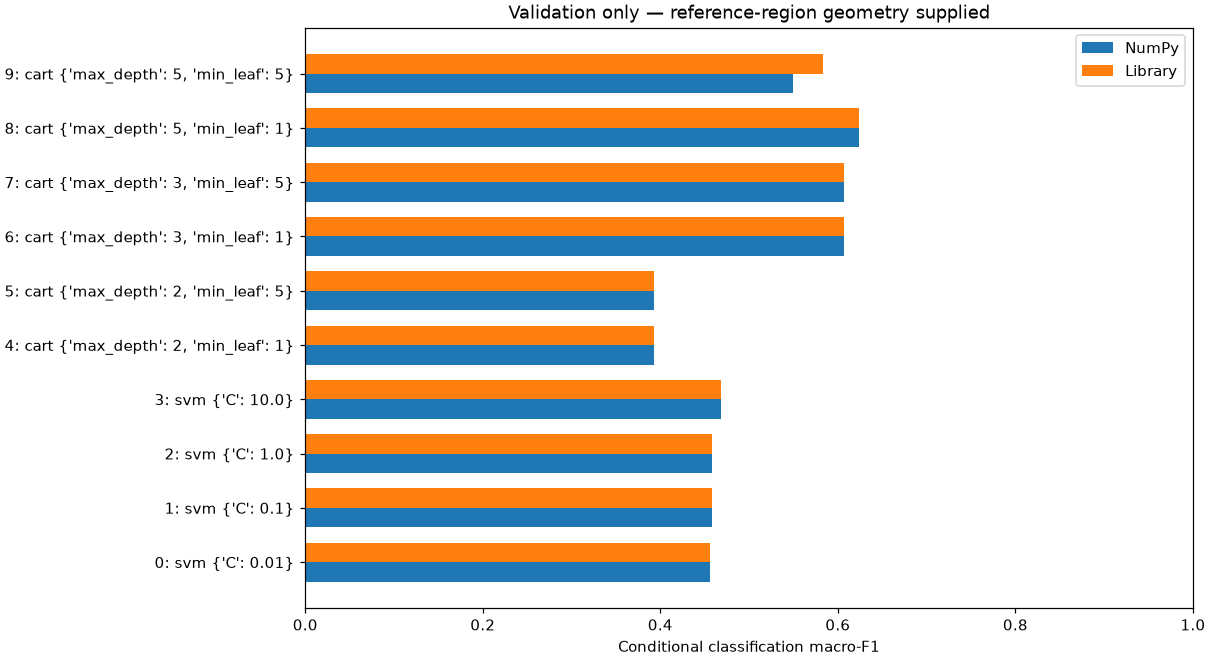

| ID | Hội tụ NumPy | Đồng thuận dự đoán | Sai số score lớn nhất |
|---:|---|---:|---:|
| 0 | True | 1.000000 | 0.000369536 |
| 1 | True | 1.000000 | 0.000106889 |
| 2 | True | 1.000000 | 0.000872298 |
| 3 | True | 1.000000 | 0.00128521 |
| 4 | True | 1.000000 | 0 |
| 5 | True | 1.000000 | 0 |
| 6 | True | 1.000000 | 0 |
| 7 | True | 1.000000 | 0.2 |
| 8 | True | 1.000000 | 0 |
| 9 | True | 0.965347 | 0.55 |

Cấu hình được chọn: 8


In [2]:
rows=classifiers['configurations']
names=[str(r['index'])+': '+r['config']['kind']+' '+str(r['config']['params']) for r in rows]
fig,ax=plt.subplots(figsize=(11,6),layout='constrained')
y=np.arange(len(rows)); width=.36
ax.barh(y-width/2,[r['numpy_validation']['macro_f1'] for r in rows],width,label='NumPy')
ax.barh(y+width/2,[r['reference_validation']['macro_f1'] for r in rows],width,label='Library')
ax.set_yticks(y,names); ax.set_xlim(0,1); ax.set_xlabel('Conditional classification macro-F1')
ax.set_title('Validation only — reference-region geometry supplied'); ax.legend(); show(fig)
table=['| ID | Hội tụ NumPy | Đồng thuận dự đoán | Sai số score lớn nhất |', '|---:|---|---:|---:|']
for r in rows:
    table.append(f"| {r['index']} | {r['numpy_converged']} | {r['prediction_agreement']:.6f} | {r['score_max_abs_difference']:.6g} |")
display(Markdown(chr(10).join(table)))
print('Cấu hình được chọn:',classifiers['winner_index'])


## So sánh 10 cấu hình tìm vùng trên validation

Cùng bộ phân lớp đã chọn; lọc/chuẩn hóa/ngưỡng/liên thông/đặc trưng có hai
cách tính. Điểm là macro-F1 của hai lớp sau khi cộng TP/FP/FN toàn validation.
Ngưỡng diện tích 64 chỉ lọc ứng viên, không bỏ nhãn nhỏ khỏi ground truth.


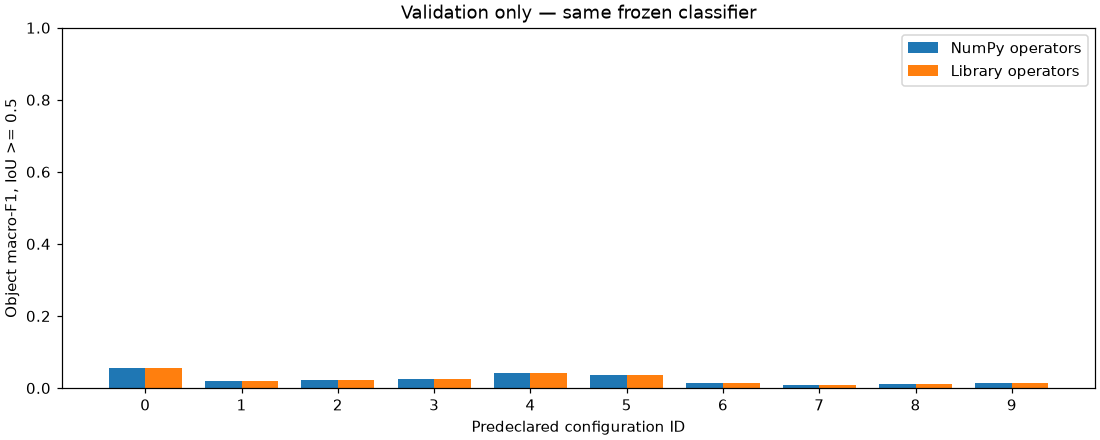

0 {'filter': 'none', 'size': 7, 'looks': 4, 'threshold': {'name': 'otsu'}, 'min_area': 64, 'morphology': 'none'}
1 {'filter': 'none', 'size': 7, 'looks': 4, 'threshold': {'name': 'niblack', 'size': 31, 'k': 0.2}, 'min_area': 64, 'morphology': 'none'}
2 {'filter': 'none', 'size': 7, 'looks': 4, 'threshold': {'name': 'niblack', 'size': 31, 'k': 0.5}, 'min_area': 64, 'morphology': 'none'}
3 {'filter': 'none', 'size': 7, 'looks': 4, 'threshold': {'name': 'niblack', 'size': 51, 'k': 0.2}, 'min_area': 64, 'morphology': 'none'}
4 {'filter': 'none', 'size': 7, 'looks': 4, 'threshold': {'name': 'niblack', 'size': 51, 'k': 0.5}, 'min_area': 64, 'morphology': 'none'}
5 {'filter': 'lee', 'size': 7, 'looks': 4, 'threshold': {'name': 'otsu'}, 'min_area': 64, 'morphology': 'none'}
6 {'filter': 'lee', 'size': 7, 'looks': 4, 'threshold': {'name': 'niblack', 'size': 31, 'k': 0.2}, 'min_area': 64, 'morphology': 'none'}
7 {'filter': 'lee', 'size': 7, 'looks': 4, 'threshold': {'name': 'niblack', 'size': 31

In [3]:
rows=candidates['configurations']
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
x=np.arange(len(rows)); width=.38
ax.bar(x-width/2,[r['numpy_summary']['macro_f1'] for r in rows],width,label='NumPy operators')
ax.bar(x+width/2,[r['reference_summary']['macro_f1'] for r in rows],width,label='Library operators')
ax.set_xticks(x,[str(r['index']) for r in rows]); ax.set_ylim(0,1)
ax.set_xlabel('Predeclared configuration ID'); ax.set_ylabel('Object macro-F1, IoU >= 0.5')
ax.set_title('Validation only — same frozen classifier'); ax.legend(); show(fig)
for r in rows: print(r['index'],r['config'])
print('Cấu hình được chọn:',candidates['winner_index'])


## Chạy lại và xem toàn bộ năm ảnh test

Mỗi hình gồm T11 đổi thang log để hiển thị, nhãn gốc và mask dự đoán NumPy.
Mask dự đoán dùng xanh lam=nền, đỏ=dầu, xanh lá=tương tự dầu. Nhãn thật còn
có đen=đất liền; không dùng đất liền trong nhãn để che dự đoán. Suy luận
không nhận nhãn thật. Đối chiếu lại cả mask NumPy và thư viện từng pixel.


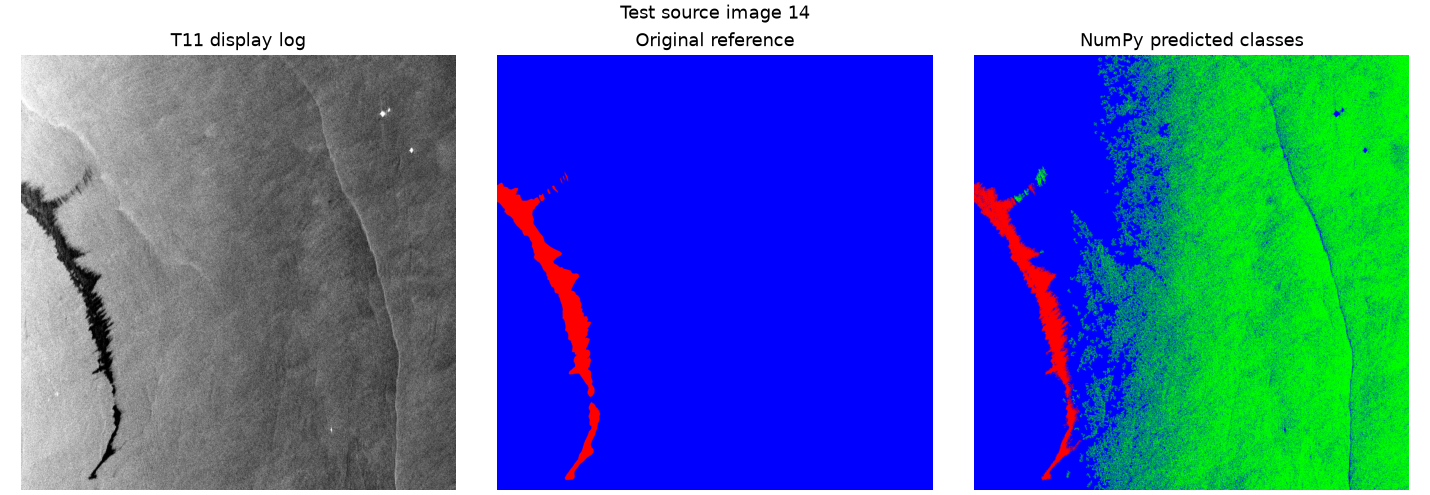

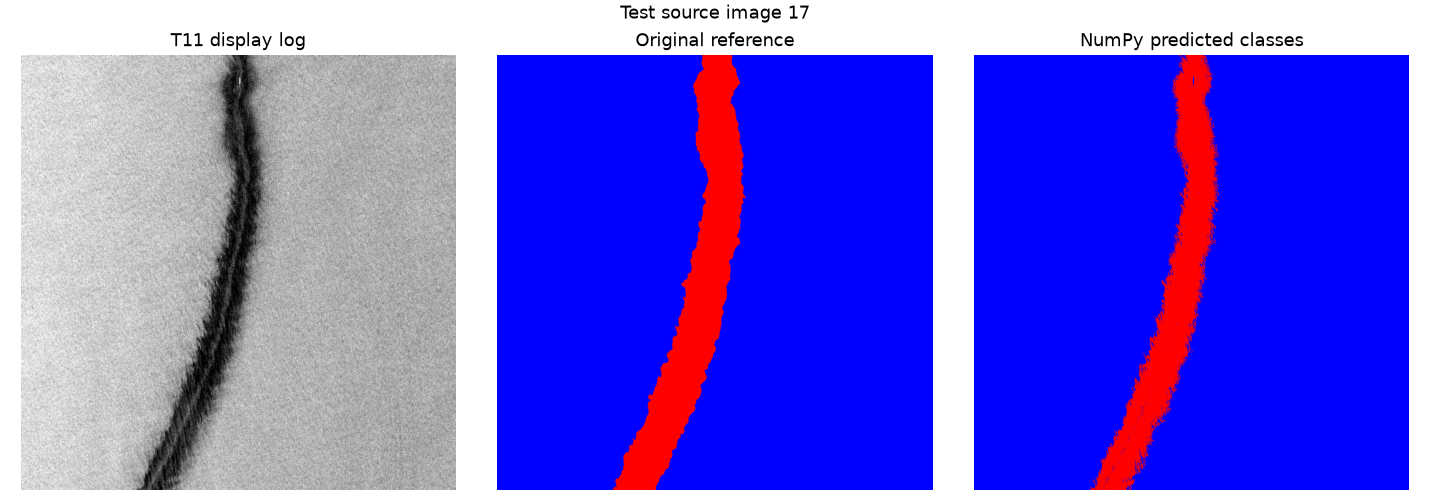

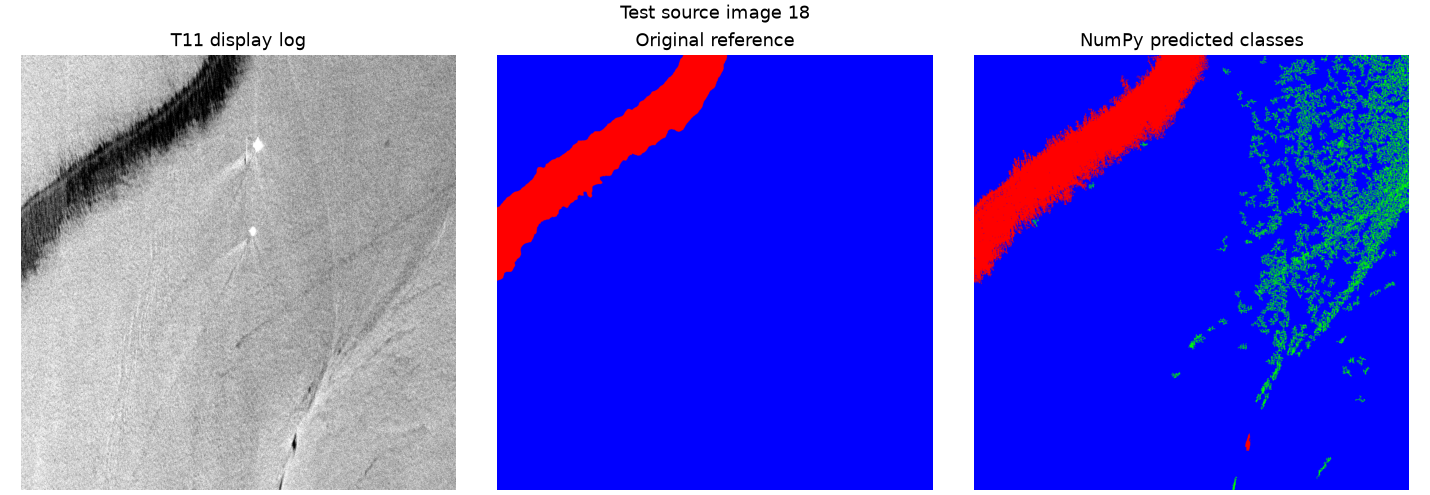

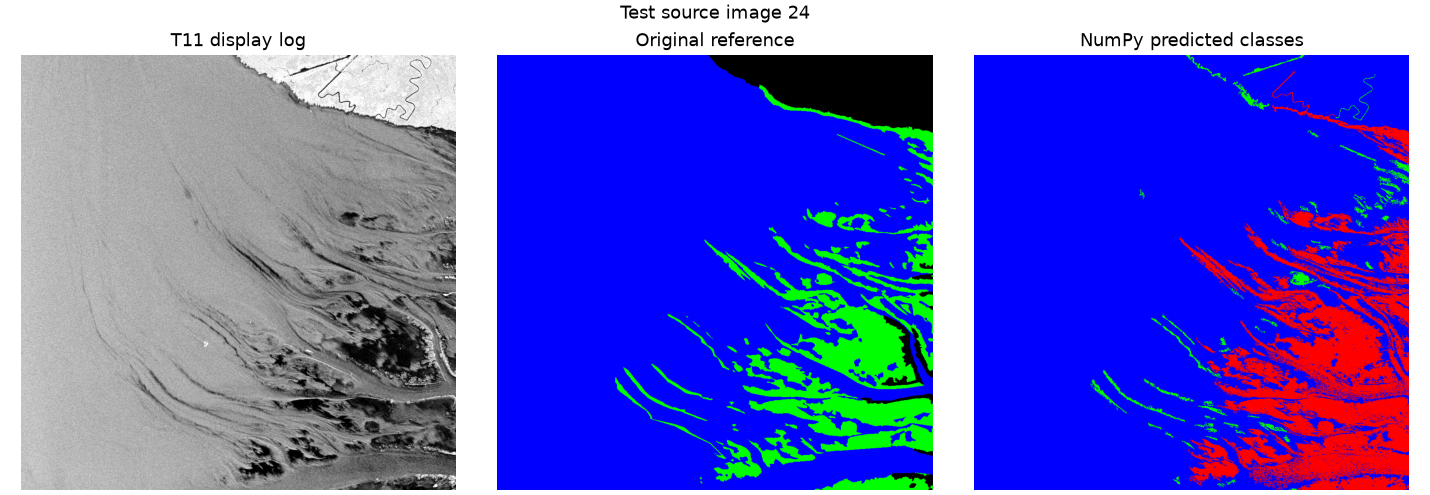

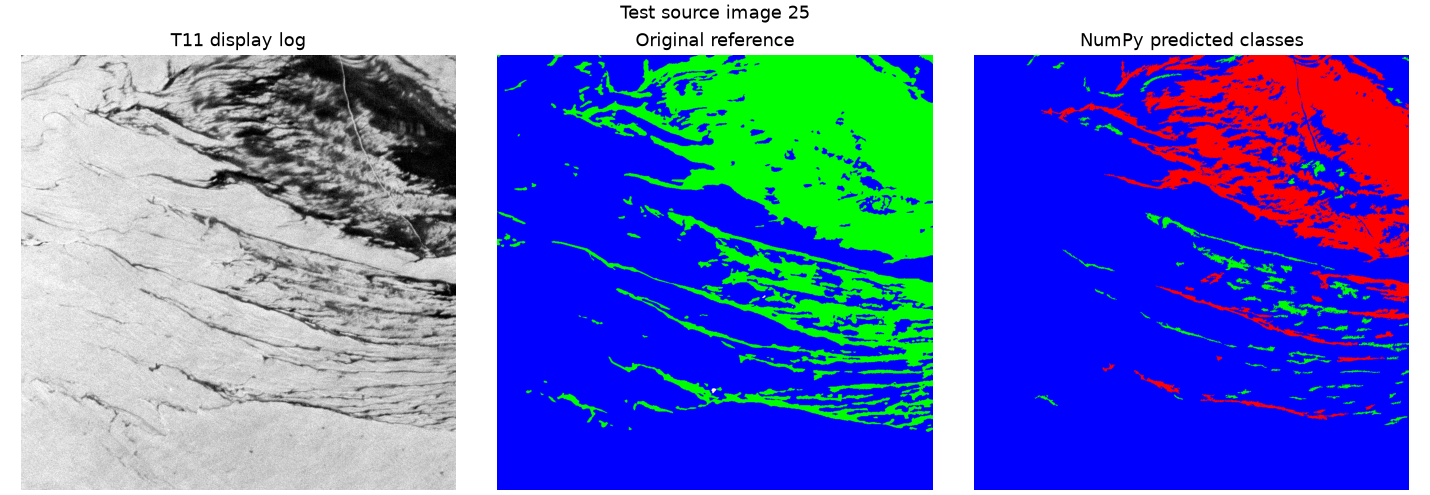

Đã chạy lại, mask và số đếm của hai backend khớp bằng chứng đã lưu.


In [4]:
from scripts._provenance import source_matches
recomputed={'numpy':[],'reference':[]}
for row in evaluation['images']:
    number=row['number']; raw,truth,source=load_pair(number)
    assert source['mat_sha256']==row['mat_sha256'] and source['mask_sha256']==row['mask_sha256']
    for backend in ('numpy','reference'):
        predicted=infer(raw,config,model,backend)['prediction']
        saved=row['saved_masks'][backend]; path=ROOT/saved['path']
        assert source_matches(path, saved['sha256'], digest(path))
        with PILImage.open(path) as im: stored=np.asarray(im)
        assert np.array_equal(predicted,stored)
        metric=detection(predicted,truth); assert metric==row[backend]
        recomputed[backend].append(metric)
        if backend=='numpy': final=predicted
    visible=10*np.log10(np.maximum(raw,1e-12)); lo,hi=np.percentile(visible,[1,99])
    palette=np.array([[0,0,255],[255,0,0],[0,255,0],[0,0,0]],dtype=np.uint8)
    reference_rgb=np.full((*truth.shape,3),255,dtype=np.uint8)
    for value in range(4): reference_rgb[truth==value]=palette[value]
    fig,axes=plt.subplots(1,3,figsize=(13,4.5),layout='constrained')
    axes[0].imshow(visible,cmap='gray',vmin=lo,vmax=hi)
    axes[1].imshow(reference_rgb); axes[2].imshow(palette[final])
    for ax,title in zip(axes,('T11 display log','Original reference','NumPy predicted classes')):
        ax.set_title(title); ax.axis('off')
    fig.suptitle(f'Test source image {number}'); show(fig)
for backend in recomputed:
    assert summarize_detections(recomputed[backend])==evaluation[backend+'_summary']
print('Đã chạy lại, mask và số đếm của hai backend khớp bằng chứng đã lưu.')


## Điểm test và nhầm lẫn

Ma trận nhầm lẫn của phát hiện chỉ tính trong các đối tượng ghép được về
không gian; số bỏ sót/phát hiện thừa được ghi riêng. Không dùng tỉ lệ nhầm
lớp có điều kiện để thay thế Recall phát hiện. Các số trên năm ảnh còn dễ
biến động; số đối tượng không phải số cảnh độc lập.


In [5]:
conditional=evaluation['conditional_rows']
recomputed_classification=classification([r['truth'] for r in conditional],[r['prediction'] for r in conditional])
assert recomputed_classification==evaluation['conditional_classification']
table=['| Phép đo | Lớp | Precision | Recall | F1 |','|---|---|---:|---:|---:|']
def fmt(value): return 'Không xác định' if value is None else f'{value:.6f}'
for label,result in [('Phân lớp có sẵn vùng',recomputed_classification),('Phát hiện đầu-cuối',evaluation['numpy_summary'])]:
    for name,row in result['classes'].items():
        table.append('| '+label+' | '+name+' | '+' | '.join(fmt(row[k]) for k in ('precision','recall','f1'))+' |')
display(Markdown(chr(10).join(table)))
print('Ma trận phân lớp có sẵn vùng:',recomputed_classification)
print('Ghép không gian và đối tượng không ghép:',evaluation['numpy_summary']['spatial_confusion'])
for name,row in evaluation['numpy_summary']['classes'].items():
    print(name,'GT <64:',row['below_64'],'GT >=64:',row['at_least_64'])


| Phép đo | Lớp | Precision | Recall | F1 |
|---|---|---:|---:|---:|
| Phân lớp có sẵn vùng | oil | 0.145161 | 0.600000 | 0.233766 |
| Phân lớp có sẵn vùng | look_alike | 0.954198 | 0.702247 | 0.809061 |
| Phát hiện đầu-cuối | oil | 0.078947 | 0.200000 | 0.113208 |
| Phát hiện đầu-cuối | look_alike | 0.009036 | 0.033708 | 0.014252 |

Ma trận phân lớp có sẵn vùng: {'class_order': ['look_alike', 'oil'], 'confusion_true_by_predicted': [[125, 53], [6, 9]], 'classes': {'oil': {'tp': 9, 'fp': 53, 'fn': 6, 'precision': np.float64(0.14516129032258066), 'recall': np.float64(0.6), 'f1': np.float64(0.23376623376623376)}, 'look_alike': {'tp': 125, 'fp': 6, 'fn': 53, 'precision': np.float64(0.9541984732824428), 'recall': np.float64(0.702247191011236), 'f1': np.float64(0.8090614886731392)}}, 'macro_f1': 0.5214138612196865, 'oil_as_look_alike_rate': 0.4, 'look_alike_as_oil_rate': 0.29775280898876405}
Ghép không gian và đối tượng không ghép: {'class_order': ['oil', 'look_alike'], 'true_by_predicted': [[3, 0], [6, 6]], 'unmatched_truth': [12, 166], 'unmatched_predictions': [29, 658], 'oil_as_look_alike_among_spatial_matches': 0.0, 'look_alike_as_oil_among_spatial_matches': 0.5, 'scope': 'Confusion rates condition on spatially matched objects; unmatched misses/false alarms are reported separately.'}
oil GT <64: {'gt': 5, 'tp': 0, 'r